# Fixed effects vs random effects: the union wage premium

**Maths for Data Science III · Panel data**

Do union members earn more than non-members? The difficulty is that union members may differ from other workers in ways we never measure: ability, motivation, the kind of firm they work for. If those hidden traits also raise wages, part of the apparent "union premium" is really a "who joins a union" premium.

Panel data (the same people observed repeatedly) give us two main tools for this problem: **fixed effects** and **random effects**. This notebook fits both to a classic dataset, compares them, tests between them, and ends with practical guidance on when to use each.

The same problem appears in healthcare data all the time. Hospitals with more nurses may also treat sicker patients. Clinicians who adopt a new protocol may already be the more careful ones. A hidden, stable trait of the unit (case mix, culture, skill) drives both the "exposure" and the outcome.

**By the end you should be able to**

1. Describe the two kinds of variation in a panel (between units and within units over time).
2. Fit fixed effects and random effects models with `linearmodels`, with standard errors clustered by unit.
3. Explain which variables a fixed-effects model can and cannot estimate, and why.
4. Run a Hausman test and its cluster-robust alternative (the Mundlak test), and interpret them.
5. Choose between fixed and random effects for a new problem and justify the choice.

## 0. Setup

If a package is missing, uncomment the `pip` line and run it once.

In [ ]:
!pip install wooldridge linearmodels statsmodels matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
import wooldridge
from linearmodels.panel import PanelOLS, RandomEffects, compare

pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

# Chart colours (one hue for data, muted ink for text and axes)
BLUE, INK, GRID = "#2a78d6", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})

## 1. The data

`wagepan` comes with Jeffrey Wooldridge's textbook *Introductory Econometrics*. It follows **545 young American men every year from 1980 to 1987** (8 years, so 4,360 rows). The data come from the National Longitudinal Survey of Youth and were first analysed by Vella and Verbeek (1998).

The variables we use:

| Variable | Meaning | Changes over time for a person? |
|---|---|---|
| `nr` | person identifier | |
| `year` | 1980 … 1987 | |
| `lwage` | log of hourly wage | yes |
| `union` | 1 if wage set by a collective bargaining agreement | yes |
| `married` | 1 if married | yes |
| `exper` | years of labour-market experience | yes (by exactly 1 a year) |
| `expersq` | `exper` squared | yes |
| `educ` | years of schooling | **no** |
| `black`, `hisp` | 1 if Black, 1 if Hispanic | **no** |
| `d81` … `d87` | year dummies (1980 is the reference year) | |

Because the outcome is in logs, a coefficient of 0.10 on `union` means union members earn roughly 10% more (more exactly, $e^{0.10}-1 = 10.5\%$).

In [2]:
raw = wooldridge.data("wagepan")
print(raw.shape)
raw[["nr", "year", "lwage", "union", "married", "exper", "educ", "black", "hisp"]].head(10)

(4360, 44)


,nr,year,lwage,union,married,exper,educ,black,hisp
0,13,1980,1.1975,0,0,1,14,0,0
1,13,1981,1.8531,1,0,2,14,0,0
2,13,1982,1.3445,0,0,3,14,0,0
3,13,1983,1.4332,0,0,4,14,0,0
4,13,1984,1.5681,0,0,5,14,0,0
5,13,1985,1.6999,0,0,6,14,0,0
6,13,1986,-0.7203,0,0,7,14,0,0
7,13,1987,1.6692,0,0,8,14,0,0
8,17,1980,1.6760,0,0,4,13,0,0
9,17,1981,1.5184,0,0,5,13,0,0


In [3]:
# Is the panel balanced (every person observed every year)?
raw.groupby("nr").size().value_counts()

8    545
Name: count, dtype: int64

Every one of the 545 men appears in all 8 years: a **balanced panel**.

`linearmodels` expects a two-level index: the unit first (`nr`), then time (`year`).

In [4]:
df = raw.set_index(["nr", "year"])
year_dummies = ["d81", "d82", "d83", "d84", "d85", "d86", "d87"]
y = df["lwage"]

## 2. Two kinds of variation

Every variable in a panel moves in two ways:

- **Between** people: some men earn more than others, on average, across all eight years.
- **Within** a person over time: a given man's wage rises and falls from year to year.

The split matters because, as we will see, **fixed effects uses only the within variation**. A variable that never changes for a person gives fixed effects nothing to work with.

The table below splits each variable's standard deviation into a between part (the spread of the person averages) and a within part (the spread of each year's deviation from the person's own average).

In [5]:
def variation_table(data, cols, unit="nr"):
    g = data.groupby(level=unit)
    rows = {}
    for c in cols:
        rows[c] = {
            "overall SD": data[c].std(),
            "between SD": g[c].mean().std(),
            "within SD": (data[c] - g[c].transform("mean")).std(),
        }
    return pd.DataFrame(rows).T

variation_table(df, ["lwage", "union", "married", "exper", "expersq", "educ", "black", "hisp"])

,overall SD,between SD,within SD
lwage,0.5326,0.3907,0.3623
union,0.4296,0.3294,0.2760
married,0.4963,0.3766,0.3236
exper,2.8259,1.6549,2.2916
expersq,40.7820,26.3513,31.1431
educ,1.7462,1.7476,0.0000
black,0.3198,0.3200,0.0000
hisp,0.3629,0.3632,0.0000


In [6]:
g = df.groupby(level="nr")
print("Share of men whose status changes at least once, 1980-87:")
for c in ["union", "married"]:
    print(f"  {c:8s} {100 * (g[c].nunique() > 1).mean():.1f}%")

print("\nYear-to-year change in exper (all men):",
      raw.sort_values(["nr", "year"]).groupby("nr")["exper"].diff().dropna().unique())

Share of men whose status changes at least once, 1980-87:
  union    45.1%
  married  56.9%

Year-to-year change in exper (all men): [1.]


Three things to notice before fitting anything:

1. **`educ`, `black` and `hisp` have zero within variation.** Nobody's schooling changed during these years (they had finished school), and race does not change. Fixed effects will not be able to estimate them.
2. **`exper` rises by exactly 1 every year for every man.** Once we remove each man's own average, experience moves in lockstep with the calendar, so it cannot be separated from the year dummies. `expersq` still varies differently across people (because $x^2$ grows faster for men with more experience), so it can stay.
3. **About 45% of the men move into or out of union coverage at least once.** These switchers are the people fixed effects learns from. A man who is always (or never) covered tells fixed effects nothing about the union premium.

Notice also that wages vary about as much within people as between them. The picture below shows why the between part matters: some men are persistently high earners and some persistently low. Each dot is one man, comparing his average wage in the first four years with his average in the last four.

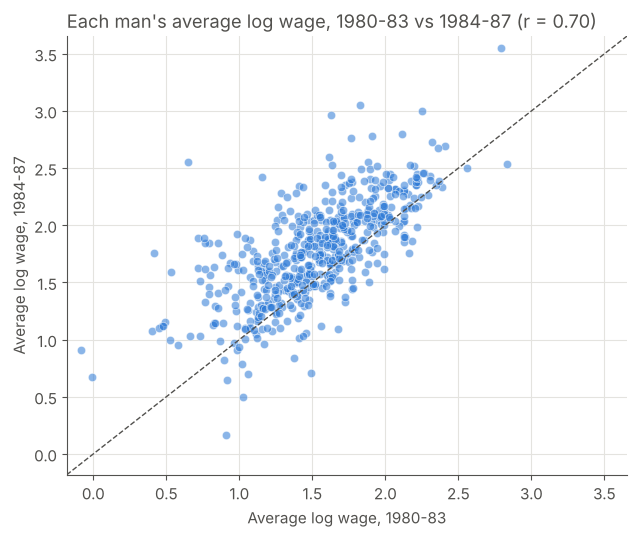

In [7]:
# Each man's average log wage in the first four years vs the last four years
early = raw[raw["year"] <= 1983].groupby("nr")["lwage"].mean()
late = raw[raw["year"] >= 1984].groupby("nr")["lwage"].mean()
r = early.corr(late)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(early, late, s=36, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.6)
lims = [min(early.min(), late.min()) - 0.1, max(early.max(), late.max()) + 0.1]
ax.plot(lims, lims, color=INK, linewidth=1, linestyle="--")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title(f"Each man's average log wage, 1980-83 vs 1984-87 (r = {r:.2f})", loc="left", color=INK)
ax.set_xlabel("Average log wage, 1980-83")
ax.set_ylabel("Average log wage, 1984-87")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Men who earned more than others in 1980-83 mostly still earned more in 1984-87: the dots run along a clear upward band. The dashed line marks equal wages in both periods; most dots sit above it because wages rise with experience for everyone. Individual years are noisy, but each man has a **persistent wage level** of his own. That stable, person-specific level is what the models below call the **individual effect**, $a_i$.

## 3. The model and the one question that matters

We write the wage equation as

$$
\text{lwage}_{it} = \beta_1\,\text{union}_{it} + \beta_2\,\text{married}_{it} + \dots + a_i + u_{it}
$$

- $i$ indexes the person and $t$ the year.
- $a_i$ is the **individual effect**: everything about person $i$ that affects wages and does not change over time, measured or not (ability, motivation, family background).
- $u_{it}$ is the ordinary year-to-year noise.

We never observe $a_i$. The whole fixed-versus-random debate comes down to one question:

> **Is the hidden individual effect $a_i$ correlated with the variables we care about (here, `union` and `married`)?**

- If **yes** (say, higher-ability men are more likely to hold union jobs), then any model that leaves $a_i$ in the error term gives biased estimates. **Fixed effects** removes $a_i$ and is the safe choice.
- If **no**, then $a_i$ is just extra noise. **Random effects** handles it efficiently and can also estimate the effects of traits that never change.

A clinical analogy: in a panel of nursing homes, $a_i$ could be each home's resident acuity. If sicker residents lead homes to hire more nurses *and* cause more adverse events, $a_i$ is correlated with staffing, and a naive comparison of staffing and outcomes will mislead.

One more consequence of $a_i$: because the same $a_i$ appears in all eight of a person's years, the errors of one person are correlated over time. Treating the eight years as eight independent pieces of evidence would overstate how much we know, so **standard errors must be clustered by person** in both models.

## 4. Fixed effects (the within estimator)

### The idea: compare each person with himself

Average the equation over the 8 years for each person and subtract that average from every year:

$$
\text{lwage}_{it} - \overline{\text{lwage}}_i = \beta_1(\text{union}_{it} - \overline{\text{union}}_i) + \dots + (a_i - a_i) + (u_{it} - \bar u_i)
$$

Because $a_i$ is the same every year, it equals its own average, and **it drops out**. We no longer need to know whether $a_i$ is correlated with `union`. Each man serves as his own control: the union effect is estimated from how a man's wage changes when *his* union status changes.

The price: anything else that is constant for a person (`educ`, `black`, `hisp`) also equals its average and drops out with $a_i$. `exper` is left out too, for the reason given in section 2.

`PanelOLS` with `entity_effects=True` does the demeaning for us.

In [8]:
fe_vars = ["expersq", "married", "union"] + year_dummies

fe = PanelOLS(y, df[fe_vars], entity_effects=True).fit(cov_type="clustered", cluster_entity=True)
print(fe.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:                  lwage   R-squared:                        0.1806
Estimator:                   PanelOLS   R-squared (Between):              0.2386
No. Observations:                4360   R-squared (Within):               0.1806
Date:                Thu, Oct 29 2026   R-squared (Overall):              0.2361
Time:                        09:52:17   Log-likelihood                   -1324.8
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      83.851
Entities:                         545   P-value                           0.0000
Avg Obs:                       8.0000   Distribution:                 F(10,3805)
Min Obs:                       8.0000                                           
Max Obs:                       8.0000   F-statistic (robust):             46.672
                            

Note the **F-test for poolability** at the bottom. It tests whether all the person effects are equal. A tiny p-value says the men really do differ in their baseline wage, so the individual effect $a_i$ is real and cannot be ignored.



### Reading the result

The fixed-effects union coefficient is about **0.08**: when a man moves into a job covered by a union contract, his wage rises by about 8%, compared with his own wages in other years. Being married is associated with about 5% higher wages on the same within-person basis.

### What fixed effects costs you

- **No estimates for time-invariant variables** (education and race here; sex, ownership type or rurality in a hospital panel).
- **Less precision.** It throws away all the between-person variation and learns only from people whose status changes.
- **Sensitivity to measurement error.** If union status is sometimes recorded wrongly, those errors look like switches, and switches are all fixed effects uses. This tends to pull the estimate towards zero.
- **It removes only *stable* confounders.** Something that changes over time and affects both union status and wages (a health problem, a change of employer) is not removed.

## 5. Random effects

### The assumption

Random effects assumes the individual effect $a_i$ is **unrelated to all the explanatory variables in every year**. Under that assumption $a_i$ is not a source of bias, just an extra piece of noise that every year of the same person shares.



In [10]:
X_re = sm.add_constant(df[["educ", "black", "hisp", "exper", "expersq", "married", "union"] + year_dummies])

re = RandomEffects(y, X_re).fit(cov_type="clustered", cluster_entity=True)
print(re.summary.tables[1])

                             Parameter Estimates                              
            Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
------------------------------------------------------------------------------
const          0.0236     0.1598     0.1476     0.8827     -0.2898      0.3369
educ           0.0919     0.0111     8.2500     0.0000      0.0700      0.1137
black         -0.1394     0.0509    -2.7391     0.0062     -0.2391     -0.0396
hisp           0.0217     0.0399     0.5449     0.5859     -0.0565      0.0999
exper          0.1058     0.0164     6.4619     0.0000      0.0737      0.1378
expersq       -0.0047     0.0008    -5.9718     0.0000     -0.0063     -0.0032
married        0.0640     0.0190     3.3753     0.0007      0.0268      0.1012
union          0.1061     0.0208     5.0959     0.0000      0.0653      0.1470
d81            0.0405     0.0275     1.4689     0.1419     -0.0135      0.0945
d82            0.0309     0.0350     0.8824     0.37



Random effects puts the union coefficient at about **0.11** (11% higher wages). It also gives us what fixed effects could not: a coefficient of about 0.09 on schooling (roughly 10% higher wages per extra year), and estimates for `black` and `hisp`. These are only trustworthy if the random-effects assumption holds, and education is a prime suspect for being correlated with unobserved ability.

## 6. The two models side by side

In [12]:
print(compare({"Fixed effects": fe, "Random effects": re}))

                    Model Comparison                   
                        Fixed effects    Random effects
-------------------------------------------------------
Dep. Variable                   lwage             lwage
Estimator                    PanelOLS     RandomEffects
No. Observations                 4360              4360
Cov. Est.                   Clustered         Clustered
R-squared                      0.1806            0.1806
R-Squared (Within)             0.1806            0.1799
R-Squared (Between)            0.2386            0.1854
R-Squared (Overall)            0.2361            0.1828
F-statistic                    83.851            68.412
P-value (F-stat)               0.0000            0.0000
=====================     ===========   ===============
expersq                       -0.0052           -0.0047
                            (-6.4058)         (-5.9718)
married                        0.0467            0.0640
                             (2.2245)          (

In [13]:
summary = pd.DataFrame({
    name: {
        "union coef": m.params["union"],
        "union SE": m.std_errors["union"],
        "union premium (%)": 100 * (np.exp(m.params["union"]) - 1),
        "married coef": m.params["married"],
        "married premium (%)": 100 * (np.exp(m.params["married"]) - 1),
    }
    for name, m in {"Fixed effects": fe, "Random effects": re}.items()
}).T
summary.round(3)

,union coef,union SE,union premium (%),married coef,married premium (%)
Fixed effects,0.080,0.023,8.329,0.047,4.779
Random effects,0.106,0.021,11.197,0.064,6.608


Random effects gives a larger union premium (about 11%) than fixed effects (about 8%), and a larger married premium too. Its standard errors are smaller, because it also uses the comparisons between different men.

Is the gap between the two models just noise, or a sign that the random-effects assumption is wrong? That is what the Hausman test asks.

## 7. Choosing between them: the Hausman test

### The logic

- If the random-effects assumption is **true**, both fixed and random effects are unbiased, and random effects is more precise. Their estimates should be close.
- If it is **false**, fixed effects is still unbiased but random effects is not. Their estimates should differ.

So a large, systematic difference between the two sets of estimates is evidence against random effects. The Hausman statistic measures that difference relative to its sampling noise:

$$
H = (\hat\beta_{FE} - \hat\beta_{RE})^\top \left[\widehat{V}_{FE} - \widehat{V}_{RE}\right]^{-1} (\hat\beta_{FE} - \hat\beta_{RE}) \;\sim\; \chi^2_k
$$

where $k$ is the number of coefficients compared.

### Two practical rules

1. **Compare only coefficients that mean the same thing in both models.** Here that is `expersq`, `married` and `union`. Not the year dummies: in the fixed-effects model they also absorb the effect of `exper`, so they estimate something different from the random-effects year dummies.
2. **The classic test uses conventional (unclustered) standard errors**, because it assumes random effects is the fully efficient estimator. So we refit both models without clustering for this test only. With clustered errors, use the Mundlak test in the next section instead.

`linearmodels` has no built-in Hausman test, but it takes five lines.

In [14]:
def hausman(fe_res, re_res, cols):
    # Classic Hausman test. Fit both models with conventional (unclustered) standard errors.
    diff = fe_res.params[cols] - re_res.params[cols]
    v_diff = fe_res.cov.loc[cols, cols] - re_res.cov.loc[cols, cols]
    stat = float(diff @ np.linalg.inv(v_diff) @ diff)
    return stat, len(cols), stats.chi2.sf(stat, len(cols))

fe_conv = PanelOLS(y, df[fe_vars], entity_effects=True).fit()
re_conv = RandomEffects(y, X_re).fit()

compared = ["expersq", "married", "union"]
H, k, p = hausman(fe_conv, re_conv, compared)
print(pd.DataFrame({"FE": fe_conv.params[compared], "RE": re_conv.params[compared],
                    "difference": fe_conv.params[compared] - re_conv.params[compared]}))
print(f"\nHausman chi2({k}) = {H:.1f}, p = {p:.1e}")

             FE      RE  difference
expersq -0.0052 -0.0047     -0.0005
married  0.0467  0.0640     -0.0173
union    0.0800  0.1061     -0.0261

Hausman chi2(3) = 28.1, p = 3.4e-06


The test rejects decisively ($p < 0.001$). The gap between the fixed- and random-effects estimates is far larger than chance would produce, so the evidence is against the random-effects assumption. **The hidden person effect is correlated with union membership and marital status, and fixed effects is the model to trust here.**

## 9. When to use each



### Summary

| | Fixed effects | Random effects |
|---|---|---|
| Assumption about hidden unit effect $a_i$ | **none**: may be related to $x$ | unrelated to $x$ |
| Variation used | within units only | blend of within and between |
| Time-invariant variables (education, sex, ownership, rurality) | **no** | yes |
| Precision | lower | higher, *if* the assumption holds |
| Main risk | imprecision; measurement error; time-varying confounders remain | bias if $a_i$ is related to $x$ |
| `wagepan` union estimate | **0.08** | 0.11 |

### Use fixed effects when

- The variable of interest **changes within units** over time, and there are enough units that change.
- It is plausible that units **self-select** into the exposure based on stable traits you cannot measure.
- The goal is the **effect of a change within a unit** ("what happens to *this* hospital's outcomes when *its* staffing rises?").
- The Hausman or Mundlak test rejects random effects (as here).

### Use random effects when

- There is a good reason to believe $a_i$ is unrelated to the regressors: most clearly when the exposure is **randomised** (a clinical trial with repeated measurements), and the tests do not reject.
- You need the effect of a **time-invariant** variable and are willing to defend the assumption.
- There is **little within-unit variation** (few switchers, short panels), so fixed effects would be too imprecise to be useful.
- You want to **predict for new units** not in the data, or describe how much units vary (the variance of $a_i$ is itself of interest, for example how much quality varies across hospitals).



### Verdict for `wagepan`

Both tests reject random effects, so we report the **fixed-effects** estimate: being covered by a union contract raises a man's wage by about **8%** ($e^{0.080}-1$), with a 95% confidence interval of roughly 4% to 13%. Random effects (about 11%) overstates it, because union members differ from non-members in stable ways that also raise their pay.

In [16]:
lo, hi = fe.conf_int().loc["union"]
print(f"Fixed-effects union premium: {100*(np.exp(fe.params['union'])-1):.1f}% "
      f"(95% CI {100*(np.exp(lo)-1):.1f}% to {100*(np.exp(hi)-1):.1f}%)")

Fixed-effects union premium: 8.3% (95% CI 3.6% to 13.3%)
